# A drink within five minutes: seven city centres

How much of each city's centre is within a 5-minute walk of a public drinking fountain? For Melbourne, Sydney, New
York, San Francisco, Paris, Barcelona and Rome, the study area is everything within 1.5 km of the city hall, inside the
city's own districts. A 5-minute walk is 400 m at 4.8 km/h, measured along OpenStreetMap's streets and paths from each
fountain; only street centrelines are counted, so a city that maps its footpaths separately is measured like one that
does not. The walks were worked out with [Plotlay](https://www.getplotlay.com)'s walking catchments. This notebook reads
only `../data`.

In [1]:
import pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
cities = pd.read_csv(f'{DATA}/tables/cities.csv').set_index('city')
districts = pd.read_csv(f'{DATA}/tables/districts.csv')
fountains = pd.read_csv(f'{DATA}/fountains/fountains.csv')
cities[['name', 'fountains', 'street_km', 'reached_km', 'streets_5min_pct', 'streets_2min_pct']]

,name,fountains,street_km,reached_km,streets_5min_pct,streets_2min_pct
city,,,,,,
MEL,Melbourne,122,153.2,149.5,97.6,48.9
SYD,Sydney,84,131.0,112.3,85.7,32.5
NYC,New York,95,93.6,82.4,88.0,34.0
SFO,San Francisco,26,146.6,73.5,50.1,8.7
PAR,Paris,103,149.4,141.8,94.9,37.7
BCN,Barcelona,180,146.8,142.1,96.8,73.5
ROM,Rome,210,147.2,145.2,98.6,71.3


## 1. The seven cities ranked

The share of street length within a 5-minute walk, recomputed from the kilometres, and the 2-minute share beside it.

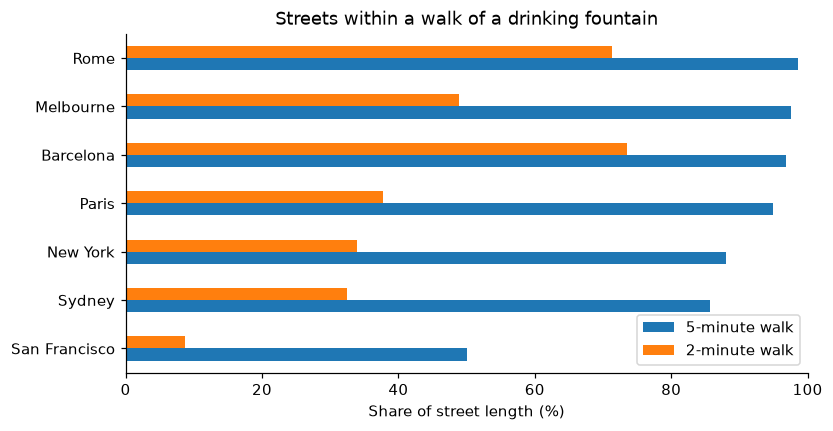

,name,share_5,streets_2min_pct,residents_5min_pct,fountains,fountains_per_km2
city,,,,,,
ROM,Rome,98.6,71.3,99.7,210,30.0
MEL,Melbourne,97.6,48.9,99.5,122,18.0
BCN,Barcelona,96.8,73.5,98.8,180,28.1
PAR,Paris,94.9,37.7,95.8,103,14.6
NYC,New York,88.0,34.0,92.6,95,18.9
SYD,Sydney,85.7,32.5,89.5,84,12.7
SFO,San Francisco,50.1,8.7,62.4,26,3.7


In [2]:
cities['share_5'] = (cities.reached_km / cities.street_km * 100).round(1)
r = cities.sort_values('share_5')
ax = r[['share_5', 'streets_2min_pct']].rename(columns={'share_5': '5-minute walk', 'streets_2min_pct': '2-minute walk'}).set_index(r.name).plot.barh(figsize=(8, 4), xlabel='Share of street length (%)', ylabel='')
ax.set_xlim(0, 100); plt.title('Streets within a walk of a drinking fountain'); plt.show()
r[['name', 'share_5', 'streets_2min_pct', 'residents_5min_pct', 'fountains', 'fountains_per_km2']].iloc[::-1]

## 2. Districts

The city share is the districts' reached kilometres over their street kilometres. The districts tile the study area, so they add up to the city (to rounding).

In [3]:
d = districts.groupby('city')[['street_km', 'reached_km']].sum()
d['share_5'] = (d.reached_km / d.street_km * 100).round(1)
d.join(cities[['name', 'share_5']].rename(columns={'share_5': 'share_5_city'}))

,street_km,reached_km,share_5,name,share_5_city
city,,,,,
BCN,146.79,142.15,96.8,Barcelona,96.8
MEL,153.22,149.54,97.6,Melbourne,97.6
NYC,93.62,82.37,88.0,New York,88.0
PAR,149.43,141.82,94.9,Paris,94.9
ROM,147.16,145.14,98.6,Rome,98.6
SFO,146.61,73.47,50.1,San Francisco,50.1
SYD,131.02,112.32,85.7,Sydney,85.7


In [4]:
big = districts[districts.area_km2 >= 0.1]
print('Districts of 0.1 km² or more with under 75% of their streets in reach:')
big[big.streets_5min_pct < 75].sort_values('streets_5min_pct')[['city', 'name', 'area_km2', 'fountains', 'street_km', 'streets_5min_pct']]

Districts of 0.1 km² or more with under 75% of their streets in reach:


,city,name,area_km2,fountains,street_km,streets_5min_pct
34,SFO,Mission,1.009,1,23.17,27.8
31,SFO,South of Market,1.535,2,31.29,30.1
43,PAR,Palais-Royal,0.134,0,2.95,36.8
25,SFO,Nob Hill,0.607,0,12.11,40.8
30,SFO,Western Addition,1.138,8,23.81,55.1
32,SFO,Hayes Valley,1.056,4,22.27,61.4
28,SFO,Japantown,0.163,0,3.21,61.7
9,SYD,Macleay Street & Woolloomooloo,0.403,1,12.18,65.4
26,SFO,Pacific Heights,0.316,2,6.37,71.2
58,PAR,Odéon,0.307,0,5.99,72.7


## 3. One city on the map

The districts coloured by the share of their streets in reach, the streets within the walk in blue and further in orange, and every fountain used.

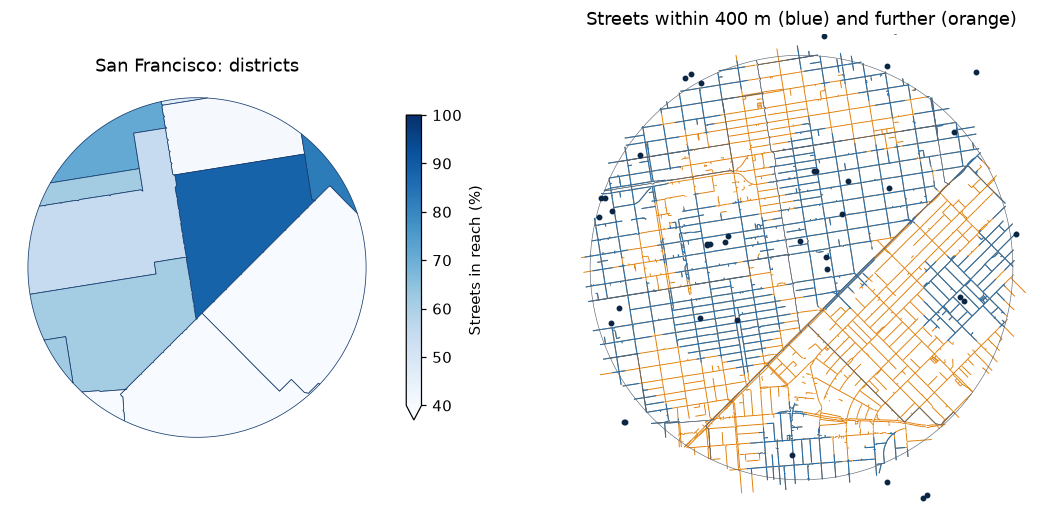

In [5]:
geo = gpd.read_file(f'{DATA}/geometry/districts.geojson')[['key', 'geometry']].merge(districts, left_on='key', right_on='district')
def city_map(code):
    s = gpd.read_file(f'{DATA}/streets/{code}_streets.geojson')
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))
    g = geo[geo.city == code]
    g.plot(column='streets_5min_pct', cmap='Blues', vmin=40, vmax=100, edgecolor='#163c6e', linewidth=0.5, legend=True, ax=axs[0], legend_kwds={'label': 'Streets in reach (%)', 'shrink': 0.6})
    axs[0].set_title(f"{cities.loc[code, 'name']}: districts")
    s[s.what == 'street'].plot(ax=axs[1], color='#e07b00', linewidth=0.6)
    s[s.what == 'reached'].plot(ax=axs[1], color='#1d6fb8', linewidth=0.7)
    f = fountains[fountains.city == code]
    axs[1].scatter(f.lng, f.lat, s=8, c='#0b2545', zorder=3)
    g.boundary.plot(ax=axs[1], color='#5b6573', linewidth=0.4)
    axs[1].set_xlim(axs[0].get_xlim()); axs[1].set_ylim(axs[0].get_ylim())
    axs[1].set_title('Streets within 400 m (blue) and further (orange)')
    for a in axs: a.set_axis_off()
    plt.show()
city_map('SFO')

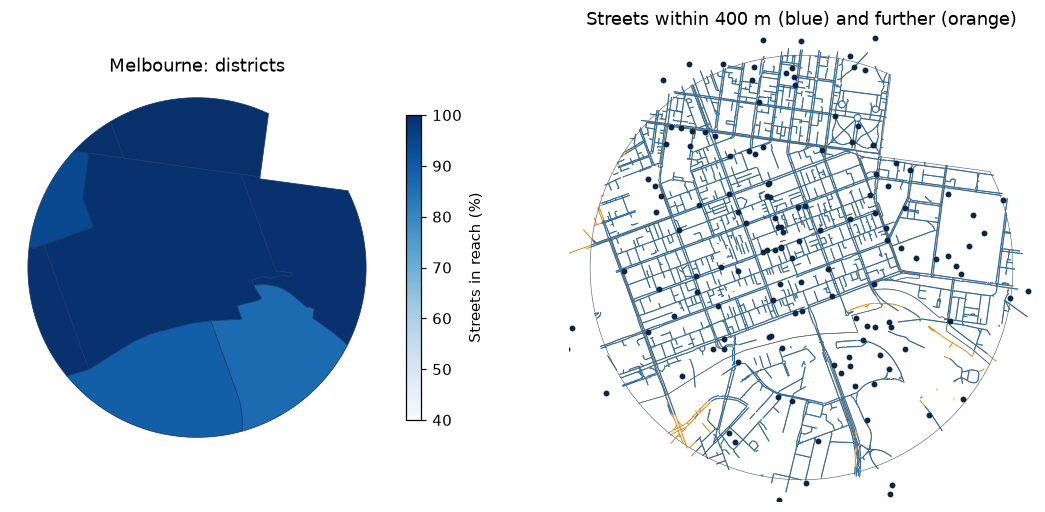

In [6]:
city_map('MEL')

## 4. How the lists compare with OpenStreetMap

The shares measured with OpenStreetMap's drinking water points in place of the city's list, and how many of the official fountains OpenStreetMap has within 30 m.

In [7]:
cities[['name', 'fountains_source', 'streets_5min_pct', 'osm_5min_pct', 'official_matched_in_osm_pct']]

,name,fountains_source,streets_5min_pct,osm_5min_pct,official_matched_in_osm_pct
city,,,,,
MEL,Melbourne,official,97.6,94.5,84.0
SYD,Sydney,official,85.7,95.9,77.0
NYC,New York,official,88.0,97.1,60.0
SFO,San Francisco,official,50.1,35.9,35.0
PAR,Paris,official,94.9,94.3,82.0
BCN,Barcelona,official,96.8,97.6,93.0
ROM,Rome,osm,98.6,98.6,NaN


## Read it carefully

- Each city records different things: New York's list is parks only, Sydney's the council's own, Barcelona's has no
  park or status field. Rome publishes no openly licensed list, so its fountains are OpenStreetMap's.
- Many fountains in New York and the European cities are turned off over winter; these shares count them all as on.
- Residents are modelled (GHS-POP 2020): each 100 m square counts by the share of its streets in reach.

Data: ODbL 1.0 (OpenStreetMap contributors, Eau de Paris and the other sources in `NOTICE`).